# Assignment 2 Deep Learning

Nama: Giganius Revo <br>
NIM: 24/541359/PA/22965

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping

In [82]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

X_train /= 255
X_test /= 255

y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (60000, 28, 28, 1)
X_test : (10000, 28, 28, 1)
y_train: (60000, 10)
y_test : (10000, 10)


In [83]:
def plot_loss(history, title):
    plt.figure(figsize=(7,4))
    
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

def plot_accuracy(history, title):
    plt.figure(figsize=(7, 4))

    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.show()

## Baseline Model

In [84]:
model_base = Sequential([
    Input(shape=(28,28,1)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_base.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_base.summary()

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_24 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8939 - loss: 0.3836 - val_accuracy: 0.9358 - val_loss: 0.2165
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9460 - loss: 0.1893 - val_accuracy: 0.9453 - val_loss: 0.1719
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9590 - loss: 0.1426 - val_accuracy: 0.9595 - val_loss: 0.1338
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9667 - loss: 0.1154 - val_accuracy: 0.9660 - val_loss: 0.1180
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9720 - loss: 0.0963 - val_accuracy: 0.9684 - val_loss: 0.1051
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9766 - loss: 0.0822 - val_accuracy: 0.9686 - val_loss: 0.1033
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9790 - loss: 0.0718 - val_accuracy: 0.9707 - val_loss: 0.0980
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9819 - loss: 0.0626 - val_accuracy: 0.

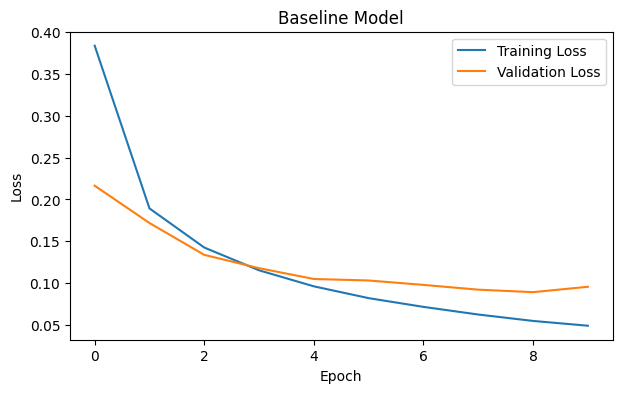

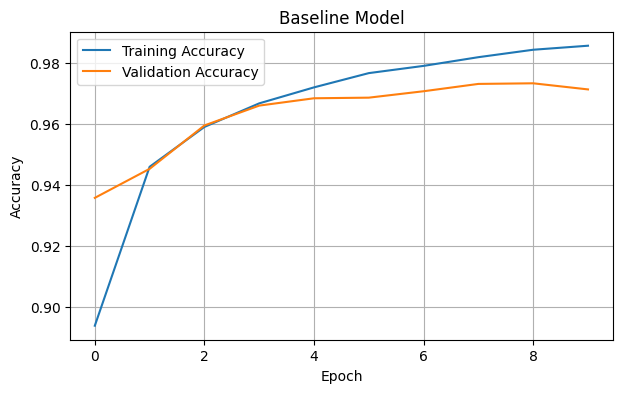

In [85]:
history_base = model_base.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

loss_base, acc_base = model_base.evaluate(X_test, y_test)
print("Test Loss: ", loss_base)
print("Test Accuracy: ", acc_base)

plot_loss(history_base, "Baseline Model")
plot_accuracy(history_base, 'Baseline Model')

model_base.save("mnist_baseline.keras")
model_load = keras.models.load_model("mnist_baseline.keras")

## L1 Regularization

In [101]:
model_l1 = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l1(0.00001)
    ),
    Dense(10, activation="softmax")
])

model_l1.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_l1.summary()

Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_30 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8957 - loss: 0.4036 - val_accuracy: 0.9406 - val_loss: 0.2277
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9479 - loss: 0.2027 - val_accuracy: 0.9550 - val_loss: 0.1738
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9611 - loss: 0.1588 - val_accuracy: 0.9607 - val_loss: 0.1537
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9671 - loss: 0.1340 - val_accuracy: 0.9658 - val_loss: 0.1379
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9722 - loss: 0.1174 - val_accuracy: 0.9685 - val_loss: 0.1266
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9761 - loss: 0.1051 - val_accuracy: 0.9681 - val_loss: 0.1280
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9781 - loss: 0.0972 - val_accuracy: 0.9719 - val_loss: 0.1141
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9806 - loss: 0.0877 - val_accuracy: 0.

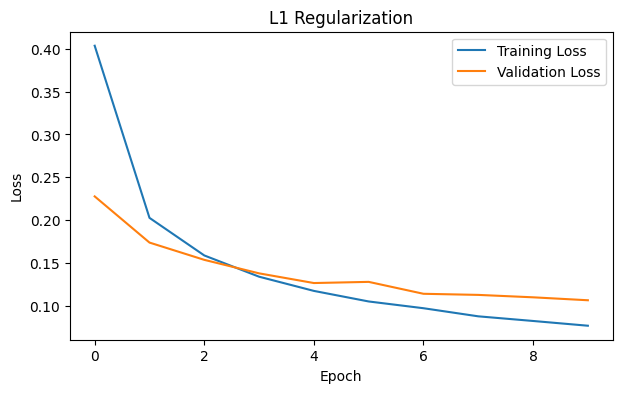

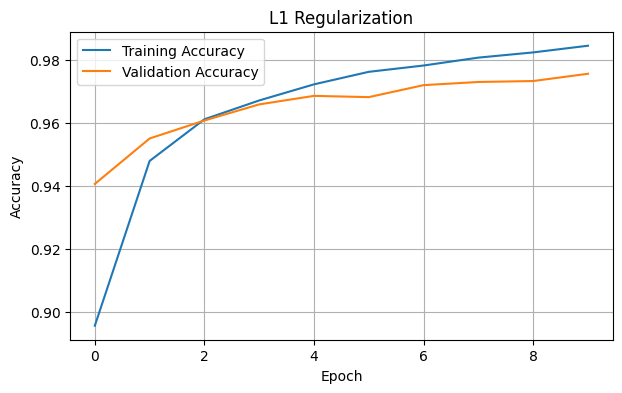

In [102]:
history_l1 = model_l1.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

train_loss = history_l1.history['loss'][-1]
train_acc = history_l1.history['accuracy'][-1]

val_loss = history_l1.history['val_loss'][-1]
val_acc = history_l1.history['val_accuracy'][-1]

print(f"L1 Training Loss       : {train_loss:.4f}")
print(f"L1 Training Accuracy   : {train_acc:.4f}")
print(f"L1 Validation Loss     : {val_loss:.4f}")
print(f"L1 Validation Accuracy : {val_acc:.4f}")
plot_loss(history_l1, "L1 Regularization")
plot_accuracy(history_l1, 'L1 Regularization')

## L2 Regularization

In [88]:
model_l2 = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),
    Dense(10, activation="softmax")
])

model_l2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_l2.summary()

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_26 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8962 - loss: 0.3945 - val_accuracy: 0.9424 - val_loss: 0.2218
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9477 - loss: 0.2028 - val_accuracy: 0.9542 - val_loss: 0.1760
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9593 - loss: 0.1632 - val_accuracy: 0.9627 - val_loss: 0.1486
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9660 - loss: 0.1400 - val_accuracy: 0.9665 - val_loss: 0.1353
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9709 - loss: 0.1234 - val_accuracy: 0.9674 - val_loss: 0.1287
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9742 - loss: 0.1128 - val_accuracy: 0.9712 - val_loss: 0.1199
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9775 - loss: 0.1033 - val_accuracy: 0.9708 - val_loss: 0.1231
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9791 - loss: 0.0970 - val_accuracy: 0.

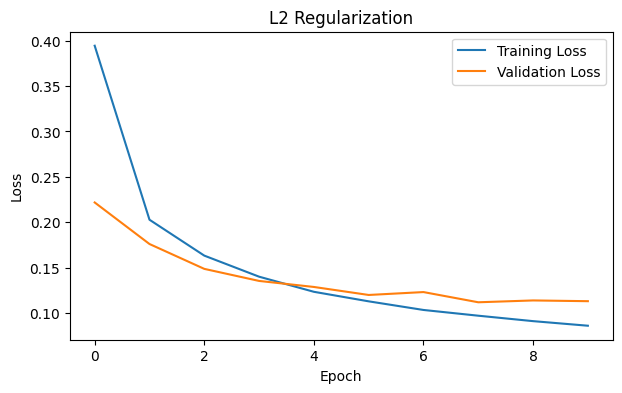

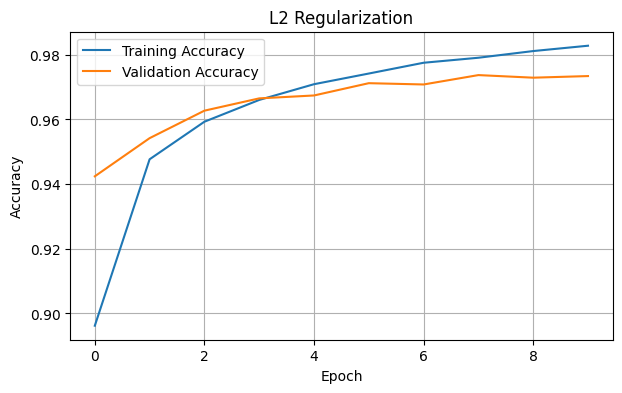

In [89]:
history_l2 = model_l2.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

train_loss_l2 = history_l2.history['loss'][-1]
train_acc_l2 = history_l2.history['accuracy'][-1]

val_loss_l2 = history_l2.history['val_loss'][-1]
val_acc_l2 = history_l2.history['val_accuracy'][-1]

print(f"L2 Training Loss       : {train_loss_l2:.4f}")
print(f"L2 Training Accuracy   : {train_acc_l2:.4f}")
print(f"L2 Validation Loss     : {val_loss_l2:.4f}")
print(f"L2 Validation Accuracy : {val_acc_l2:.4f}")

plot_loss(history_l2, "L2 Regularization")
plot_accuracy(history_l2, 'L2 Regularization')

## Dropout

In [90]:
model_dropout = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_dropout.summary()

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_27 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8523 - loss: 0.5072 - val_accuracy: 0.9333 - val_loss: 0.2244
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9229 - loss: 0.2654 - val_accuracy: 0.9526 - val_loss: 0.1655
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9381 - loss: 0.2132 - val_accuracy: 0.9590 - val_loss: 0.1398
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9447 - loss: 0.1892 - val_accuracy: 0.9635 - val_loss: 0.1247
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9504 - loss: 0.1689 - val_accuracy: 0.9644 - val_loss: 0.1172
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9543 - loss: 0.1551 - val_accuracy: 0.9678 - val_loss: 0.1073
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9568 - loss: 0.1455 - val_accuracy: 0.9685 - val_loss: 0.1022
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9596 - loss: 0.1355 - val_accuracy: 0.

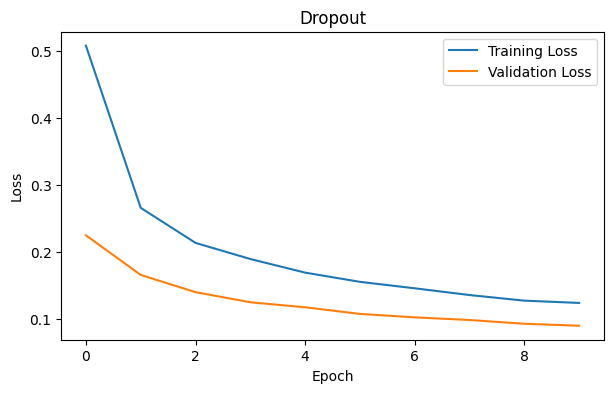

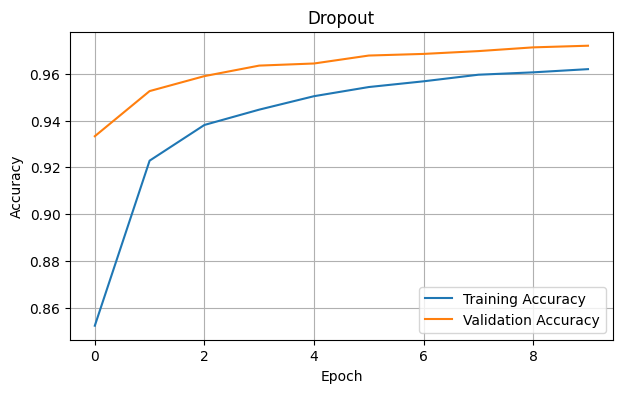

In [91]:
history_dropout = model_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

train_loss_dropout = history_dropout.history['loss'][-1]
train_acc_dropout = history_dropout.history['accuracy'][-1]

val_loss_dropout = history_dropout.history['val_loss'][-1]
val_acc_dropout = history_dropout.history['val_accuracy'][-1]

print(f"Dropout Training Loss       : {train_loss_dropout:.4f}")
print(f"Dropout Training Accuracy   : {train_acc_dropout:.4f}")
print(f"Dropout Validation Loss     : {val_loss_dropout:.4f}")
print(f"Dropout Validation Accuracy : {val_acc_dropout:.4f}")

plot_loss(history_dropout, "Dropout")
plot_accuracy(history_dropout, 'Dropout')

## Early Stopping

In [92]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_early = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_early.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_early.summary()

Model: "sequential_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_28 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8899 - loss: 0.3933 - val_accuracy: 0.9348 - val_loss: 0.2312
Epoch 2/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9429 - loss: 0.2022 - val_accuracy: 0.9503 - val_loss: 0.1704
Epoch 3/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9551 - loss: 0.1545 - val_accuracy: 0.9584 - val_loss: 0.1401
Epoch 4/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9637 - loss: 0.1251 - val_accuracy: 0.9650 - val_loss: 0.1218
Epoch 5/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9696 - loss: 0.1049 - val_accuracy: 0.9671 - val_loss: 0.1130
Epoch 6/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9741 - loss: 0.0892 - val_accuracy: 0.9700 - val_loss: 0.1024
Epoch 7/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9767 - loss: 0.0781 - val_accuracy: 0.9730 - val_loss: 0.0959
Epoch 8/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9797 - loss: 0.0685 - val_accuracy: 0.

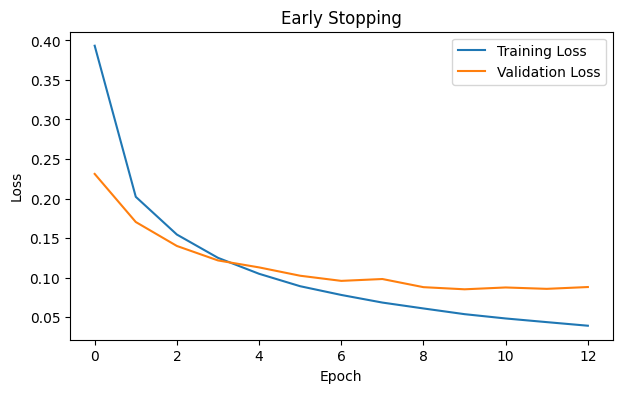

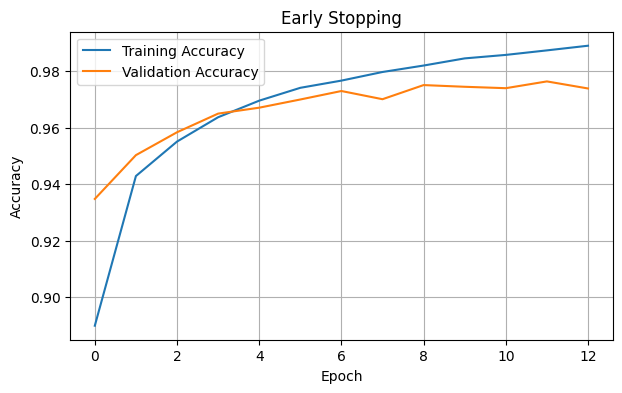

In [93]:
history_early = model_early.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=100,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)


train_loss_early = history_early.history['loss'][-1]
train_acc_early = history_early.history['accuracy'][-1]

val_loss_early = history_early.history['val_loss'][-1]
val_acc_early = history_early.history['val_accuracy'][-1]

best_epoch_early = history_early.history['val_loss'].index(val_loss_early)
print("Best Epoch                        :", best_epoch_early + 1)

print(f"Early Stopping Training Loss       : {train_loss_early:.4f}")
print(f"Early Stopping Training Accuracy   : {train_acc_early:.4f}")
print(f"Early Stopping Validation Loss     : {val_loss_early:.4f}")
print(f"Early Stopping Validation Accuracy : {val_acc_early:.4f}")


plot_loss(history_early, "Early Stopping")
plot_accuracy(history_early, 'Early Stopping')

## L1 + Dropout

In [94]:
model_l1_dropout = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l1(0.00001)
    ),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model_l1_dropout.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_l1_dropout.summary()

Model: "sequential_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_29 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8511 - loss: 0.5317 - val_accuracy: 0.9321 - val_loss: 0.2558
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9194 - loss: 0.2970 - val_accuracy: 0.9471 - val_loss: 0.2010
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9334 - loss: 0.2488 - val_accuracy: 0.9548 - val_loss: 0.1730
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9415 - loss: 0.2209 - val_accuracy: 0.9607 - val_loss: 0.1547
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9471 - loss: 0.2030 - val_accuracy: 0.9646 - val_loss: 0.1406
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9515 - loss: 0.1877 - val_accuracy: 0.9666 - val_loss: 0.1344
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9549 - loss: 0.1781 - val_accuracy: 0.9654 - val_loss: 0.1315
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9566 - loss: 0.1692 - val_accuracy: 0.

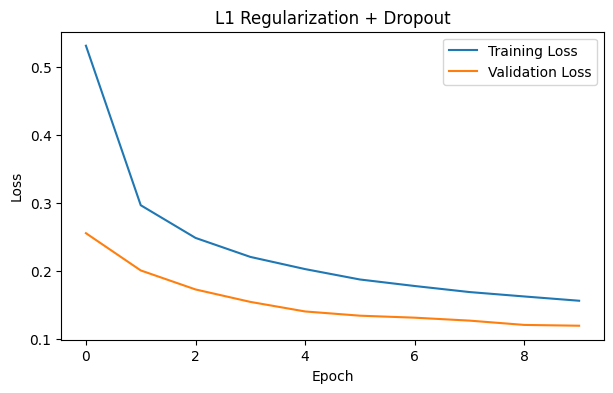

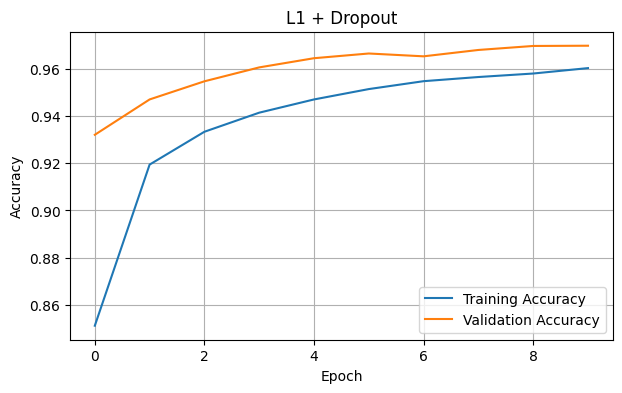

In [95]:
history_l1_dropout = model_l1_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

train_loss_l1_dropout = history_l1_dropout.history['loss'][-1]
train_acc_l1_dropout = history_l1_dropout.history['accuracy'][-1]

val_loss_l1_dropout = history_l1_dropout.history['val_loss'][-1]
val_acc_l1_dropout = history_l1_dropout.history['val_accuracy'][-1]

print(f"L1 + Dropout Training Loss       : {train_loss_l1_dropout:.4f}")
print(f"L1 + Dropout Training Accuracy   : {train_acc_l1_dropout:.4f}")
print(f"L1 + Dropout Validation Loss     : {val_loss_l1_dropout:.4f}")
print(f"L1 + Dropout Validation Accuracy : {val_acc_l1_dropout:.4f}")

plot_loss(history_l1_dropout, "L1 Regularization + Dropout")
plot_accuracy(history_l1_dropout, 'L1 + Dropout')